# Feature Importance

## 1. What is Feature Importance?

Feature Importance is a technique used to understand how much each input feature contributes to a Machine Learning model's predictions.

A dataset may contain many features, but some features may contribute more useful information than others.

Example:

A telecom company wants to predict customer churn using:

- Age
- Tenure
- MonthlyCharges
- TotalCharges
- ContractType
- SupportCalls

Feature Importance helps identify which of these features are most influential in the trained model.

## 2. Why is Feature Importance Important?

Feature Importance helps:

- Identify influential input features.
- Understand model behaviour.
- Improve model interpretability.
- Support feature selection decisions.
- Identify potentially unnecessary features.
- Communicate model findings to business teams.

Important: A feature's importance does not automatically prove that it causes the target outcome.

## 3. Feature Importance vs Feature Selection

| Feature Importance | Feature Selection |
|---|---|
| Measures feature contribution or usefulness | Selects a subset of features |
| Helps rank features | Helps retain or remove features |
| Example: Tenure has a high importance score | Example: Retain Tenure and remove an irrelevant identifier |
| Used for model interpretation | Used to prepare model inputs |

Feature Importance can support Feature Selection.

## 4. Tree-Based Feature Importance

Decision Tree and Random Forest models can calculate feature importance based on reductions in impurity.

Examples:

- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting

A feature that produces larger impurity reductions across the model may receive a higher importance score.

Scikit-learn provides:

`feature_importances_`

Important: Tree-based impurity importance can favour features with many possible split points or high cardinality.

## 5. Random Forest Feature Importance

Random Forest combines predictions from multiple decision trees.

It calculates feature importance by aggregating the impurity reductions across its trees.

Example:

| Feature | Importance |
|---|---:|
| Tenure | 0.35 |
| ContractType | 0.25 |
| MonthlyCharges | 0.20 |
| SupportCalls | 0.15 |
| Age | 0.05 |

The scores generally sum to 1.

Higher scores indicate greater contribution according to this particular importance calculation.

## 6. Permutation Importance

Permutation Importance measures how much model performance changes when the values of one feature are randomly shuffled.

Process:

1. Calculate model performance using the original data.
2. Shuffle one feature's values.
3. Calculate performance again.
4. Compare the performance difference.
5. Repeat for other features.

If performance decreases significantly after shuffling a feature, that feature may be important to the model.

Scikit-learn provides:

`permutation_importance()`

Advantages:

- Can be used with different model types.
- Measures importance based on model performance.
- Can be applied to a held-out dataset.

Limitations:

- Can be misleading when features are highly correlated.
- Results depend on the evaluation dataset and scoring metric.
- Requires additional computation.

## 7. SHAP (SHapley Additive exPlanations)

SHAP is a method used to explain individual predictions and overall model behaviour.

It uses concepts from cooperative game theory to estimate each feature's contribution to a prediction.

SHAP can help answer:

- Which features influenced a prediction?
- Did a feature increase or decrease the prediction?
- How important is a feature across many predictions?

SHAP is useful for more detailed model explanations.

## 8. Global and Local Feature Importance

### Global Feature Importance

Explains which features are important across the complete dataset or a large group of predictions.

Example:

Tenure is one of the most influential features across the customer population.

### Local Feature Importance

Explains which features influenced one particular prediction.

Example:

For one customer, short tenure and high support-call frequency may contribute to a higher predicted churn probability.

## 9. Correlated Features and Importance

When two features contain similar information, importance may be distributed between them.

For example:

- Tenure
- TotalCharges

These features may be strongly related.

One feature may receive lower importance because another correlated feature provides similar information.

Therefore, low importance does not always mean a feature contains no useful information.

## 10. Important Considerations

- Feature importance depends on the trained model.
- Importance does not prove causation.
- Compare different importance methods when appropriate.
- Check highly correlated features.
- Use validation or test data for permutation importance.
- Avoid interpreting importance from leaked features.
- Consider business knowledge before removing features.

## Conclusion

Feature Importance helps us understand how input features contribute to Machine Learning predictions.

Tree-based importance, Permutation Importance, and SHAP provide different ways to interpret model behaviour.

Feature importance should support, not replace, careful feature selection and model validation.

# Demonstration: Feature Importance in Telecom Customer Churn

## Business Scenario

A telecom company wants to understand which customer characteristics are most useful for predicting customer churn.

The company collects:

- Tenure
- MonthlyCharges
- TotalCharges
- ContractType
- SupportCalls
- Age

The target variable is:

`Churn`

- 0 = Customer stays.
- 1 = Customer leaves.

## Example 1: Random Forest Importance

Suppose a trained Random Forest model produces:

| Feature | Importance |
|---|---:|
| Tenure | 0.32 |
| ContractType | 0.27 |
| SupportCalls | 0.20 |
| MonthlyCharges | 0.12 |
| TotalCharges | 0.06 |
| Age | 0.03 |

Interpretation:

Tenure has the highest importance score in this example.

It contributes more to the model's impurity-based importance calculation than the other features.

## Example 2: Permutation Importance

Suppose the model achieves an accuracy of 85%.

We randomly shuffle the Tenure column and the accuracy decreases to 72%.

This suggests that the model relies on information contained in Tenure.

If shuffling Age causes almost no performance change, Age may have lower predictive importance for this model.

## Example 3: Global Importance

Global importance explains the features that influence predictions across many customers.

Example:

Tenure and ContractType may be influential across the overall customer population.

## Example 4: Local Importance

Local importance explains a single prediction.

Example:

For one customer, the model predicts a high churn probability.

Possible contributing features:

- Short tenure
- High support-call frequency
- Monthly contract

These features may help explain that particular prediction.

## Example 5: Business Interpretation

Feature Importance helps the telecom company:

- Identify customer characteristics associated with churn predictions.
- Understand model behaviour.
- Prioritize further customer analysis.
- Communicate findings to business teams.
- Investigate possible customer retention strategies.

## Important Note

Feature importance describes the model's behaviour, not necessarily the real-world causes of churn.

A high importance score does not prove that changing a feature will change customer behaviour.

Original Dataset:
   Tenure  MonthlyCharges  TotalCharges  SupportCalls  Age  ContractType  \
0      52       75.281998   3950.680780             0   53             2   
1      15       49.651014    916.625153             6   21             1   
2      72       61.978086   4549.029218             0   31             1   
3      61       45.620694   2772.504746             3   58             2   
4      21       81.151371   1726.186226             1   58             0   

   Churn  
0      0  
1      1  
2      0  
3      1  
4      1  

Dataset Shape:
(300, 7)

Input Features:
['Tenure', 'MonthlyCharges', 'TotalCharges', 'SupportCalls', 'Age', 'ContractType']

Target Variable:
Churn

Training Shape: (240, 6)
Testing Shape: (60, 6)

Random Forest Model Trained Successfully!

Model Accuracy:
0.7167

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.62      0.64        24
           1       0.76      0.78      0.77        36

    a

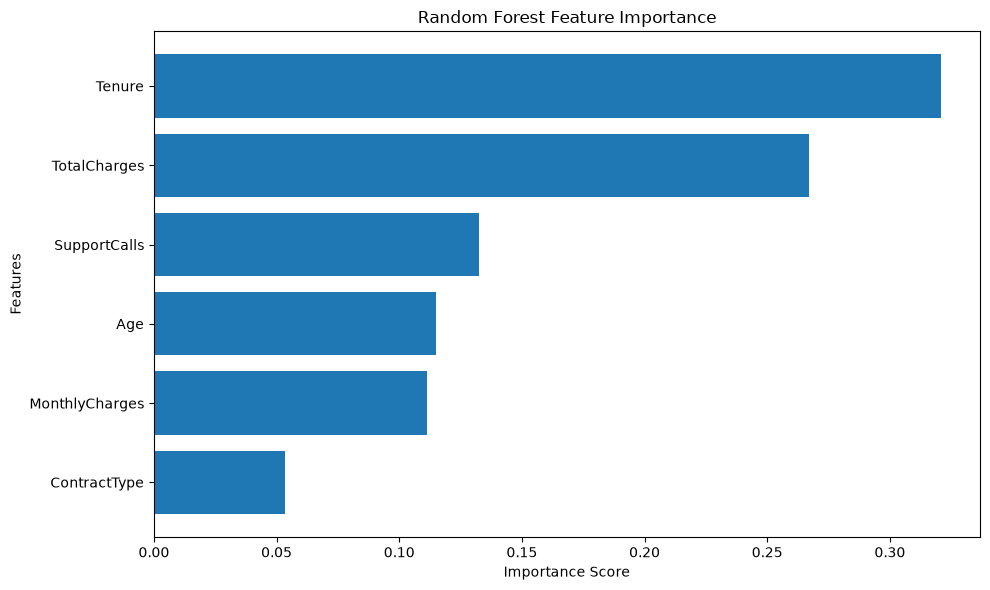


Permutation Importance:
          Feature  Importance_Mean  Importance_Std
0          Tenure         0.195000        0.035785
3    SupportCalls         0.043333        0.023805
1  MonthlyCharges         0.028333        0.018333
2    TotalCharges         0.020000        0.027689
4             Age        -0.005000        0.016750
5    ContractType        -0.011667        0.025874


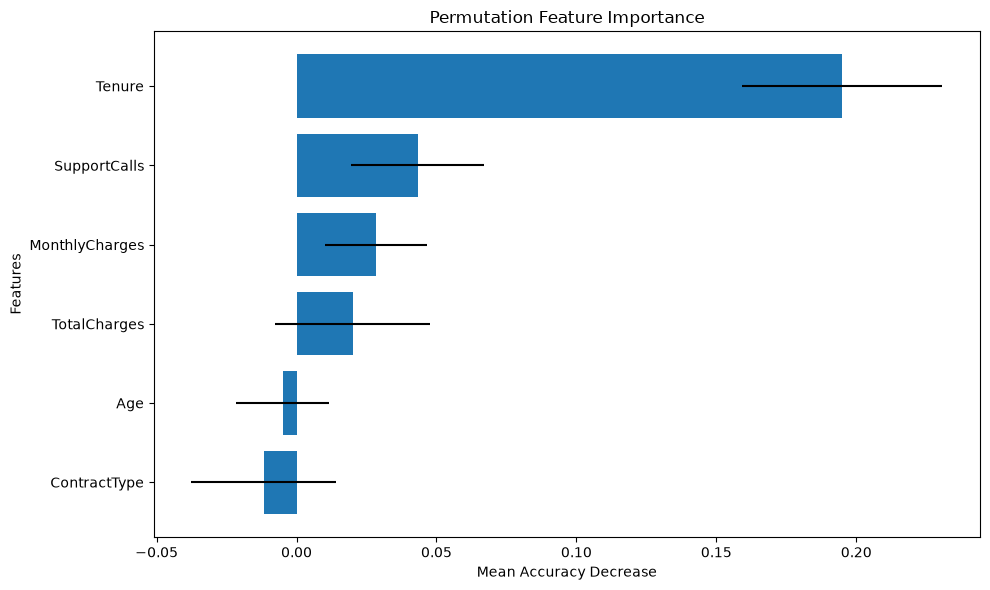


Feature Importance Comparison:
          Feature  Importance  Importance_Mean  Importance_Std
0          Tenure    0.320695         0.195000        0.035785
1    TotalCharges    0.266940         0.020000        0.027689
2    SupportCalls    0.132651         0.043333        0.023805
3             Age    0.115176        -0.005000        0.016750
4  MonthlyCharges    0.111217         0.028333        0.018333
5    ContractType    0.053321        -0.011667        0.025874

Features Above Importance Threshold:
['Tenure', 'TotalCharges', 'SupportCalls', 'Age', 'MonthlyCharges']

Feature Importance Summary
Total Input Features: 6
Important Features: 5
Important Feature Names: ['Tenure', 'TotalCharges', 'SupportCalls', 'Age', 'MonthlyCharges']

Feature Importance Analysis Completed!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report

# ---------------------------------------
# 1. Create sample telecom dataset
# ---------------------------------------

np.random.seed(42)

n = 300

tenure = np.random.randint(1, 73, n)

monthly_charges = np.random.uniform(20, 120, n)

total_charges = (
    tenure * monthly_charges
    + np.random.normal(0, 100, n)
)

support_calls = np.random.poisson(2, n)

age = np.random.randint(18, 70, n)

contract_type = np.random.choice(
    [0, 1, 2],
    size=n
)

# Create churn probability
churn_probability = (
    0.75
    - 0.012 * tenure
    + 0.12 * support_calls
    + 0.15 * (contract_type == 0)
)

churn_probability = np.clip(
    churn_probability,
    0.05,
    0.95
)

churn = np.random.binomial(
    1,
    churn_probability
)

df = pd.DataFrame({
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "TotalCharges": total_charges,
    "SupportCalls": support_calls,
    "Age": age,
    "ContractType": contract_type,
    "Churn": churn
})

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


# ---------------------------------------
# 2. Separate Features and Target
# ---------------------------------------

X = df.drop(columns=["Churn"])

y = df["Churn"]

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)


# ---------------------------------------
# 3. Train-Test Split
# ---------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


# ---------------------------------------
# 4. Train Random Forest Model
# ---------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

rf_model.fit(
    X_train,
    y_train
)

print("\nRandom Forest Model Trained Successfully!")


# ---------------------------------------
# 5. Make Predictions
# ---------------------------------------

y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nModel Accuracy:")
print(round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# ---------------------------------------
# 6. Random Forest Feature Importance
# ---------------------------------------

importance_results = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance_results = importance_results.sort_values(
    by="Importance",
    ascending=False
)

print("\nRandom Forest Feature Importance:")
print(importance_results)


# ---------------------------------------
# 7. Visualize Feature Importance
# ---------------------------------------

plt.figure(figsize=(10, 6))

plt.barh(
    importance_results["Feature"],
    importance_results["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ---------------------------------------
# 8. Permutation Importance
# ---------------------------------------

permutation_results = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

print("\nPermutation Importance:")
print(permutation_df)


# ---------------------------------------
# 9. Visualize Permutation Importance
# ---------------------------------------

plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance_Mean"],
    xerr=permutation_df["Importance_Std"]
)

plt.xlabel("Mean Accuracy Decrease")
plt.ylabel("Features")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ---------------------------------------
# 10. Compare Importance Methods
# ---------------------------------------

comparison_df = importance_results.merge(
    permutation_df,
    on="Feature"
)

comparison_df = comparison_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance Comparison:")
print(comparison_df)


# ---------------------------------------
# 11. Identify High-Importance Features
# ---------------------------------------

importance_threshold = 0.10

important_features = importance_results[
    importance_results["Importance"] >= importance_threshold
]["Feature"].tolist()

print("\nFeatures Above Importance Threshold:")
print(important_features)


# ---------------------------------------
# 12. Final Summary
# ---------------------------------------

print("\nFeature Importance Summary")

print("Total Input Features:", X.shape[1])

print("Important Features:", len(important_features))

print("Important Feature Names:", important_features)

print("\nFeature Importance Analysis Completed!")

# Feature Justification – Feature Importance

## 1. Feature Importance Analysis

Feature Importance helps identify which input variables contribute to a trained model's predictions.

We used two methods:

1. Random Forest Feature Importance
2. Permutation Importance

Both methods provide different perspectives.

## 2. Feature Justification Table

| Feature Name | Source Columns | Feature Logic / Formula | Reason for Creation | Expected Relationship with Target | Business Meaning | Potential ML Value | Leakage Risk | Final Decision |
|---|---|---|---|---|---|---|---|---|
| Tenure | Tenure | Original numerical value | Measure customer relationship duration | Longer tenure may be associated with lower churn | Customer loyalty duration | Potentially useful for churn prediction | Low if measured at prediction time | Retain |
| MonthlyCharges | MonthlyCharges | Original numerical value | Measure monthly spending | Relationship depends on pricing and customer behaviour | Monthly service spending | May help identify spending patterns | Low if available at prediction time | Retain |
| TotalCharges | TotalCharges | Original numerical value | Measure accumulated spending | May be related to tenure and churn | Historical customer spending | Provides spending history | Medium if calculated using future transactions | Needs Further Analysis |
| SupportCalls | SupportCalls | Number of support calls | Understand support activity | More complaints may be associated with churn | Customer support activity | May help identify dissatisfied customers | High if calls occur after prediction time | Retain with time validation |
| Age | Age | Original numerical value | Understand customer demographics | Depends on customer behaviour | Customer age | May provide demographic information | Low if available at prediction time | Needs Further Analysis |
| ContractType | ContractType | Encoded contract category | Understand contract commitment | Contract type may be associated with churn | Customer contract category | May help distinguish customer behaviour | Low if known at prediction time | Retain |

## 3. Importance Method Comparison

### Random Forest Feature Importance

- Based on impurity reduction.
- Calculated during model training.
- Useful for understanding tree-based model behaviour.
- Can favour features with many possible split points.

### Permutation Importance

- Measures performance reduction after feature shuffling.
- Can be applied to different model types.
- Useful for understanding the impact of a feature on predictive performance.
- Can be affected by correlated features.

## 4. Feature Selection Decisions

### Features to Investigate and Retain

Features with consistently useful importance across different methods and validation runs should be considered for retention.

### Features Requiring Further Analysis

Features with low importance should be checked for:

- Correlation with other features.
- Business relevance.
- Non-linear relationships.
- Performance changes when removed.

Do not remove a feature based only on one importance score.

## 5. Leakage Prevention

Feature importance analysis must use valid input features.

Important precautions:

- Do not include the target column as an input feature.
- Remove information that would not be available at prediction time.
- Train the model using training data only.
- Use validation or held-out test data for permutation importance.
- Do not select features based on repeated test-set experimentation.

## 6. Final Conclusion

Feature Importance helps explain which features contribute to Machine Learning predictions.

Random Forest importance and Permutation Importance provide useful but different measurements.

Feature importance can support model interpretation and feature selection, but final decisions should consider model validation, correlation, business knowledge, and data leakage.